# Проект. Исследование стартапов

## Введение

Необходимо рассмотреть датасет с данными о стартапах по 2014 год. Выяснить для компании осуществляющей венчурные инвестиции, перспективы выхода на рынок. Для этого необходимо провести очистку и фильтрацию данных, разделить данные на группы по сегментам. Определить аномальные значения и привести данные к корректному виду без выбросов. Сравнить популярность и объемы разных типов финансирования. Проанализировать динамику раундов и объёмов инвестиций по годам, а также изменения в массовых сегментах рынка. Рассчитать долю возврата средств для разных типов финансирования и оценить её устойчивость. Подвести итоговые выводы и дать рекомендации, куда и каким образом было бы целесообразно инвестировать, если бы на дворе был 2015 год.

## Шаг 1. Знакомство с данными: загрузка и предобработка

Датасет получен из базы данных стартапов.

Название основного датасета — `cb_investments.zip`. Внутри архива один файл — `cb_investments.csv`.

Описание данных:
* `name` — название компании.
* `homepage_url` — ссылка на сайт компании.
* `category_list` — категории, в которых работает компания. Указываются через `|`.
* `market` — основной рынок или отрасль компании.
* `funding_total_usd` — общий объём привлечённых инвестиций в долларах США.
* `status` — текущий статус компании, например `operating`, `closed` и так далее.
* `country_code` — код страны, например USA.
* `state_code` — код штата или региона, например, CA.
* `region` — регион, например, SF Bay Area.
* `city` — город, в котором расположена компания.
* `funding_rounds` — общее число раундов финансирования.
* `participants` — число участников в раундах финансирования.
* `founded_at` — дата основания компании.
* `founded_month` — месяц основания в формате `YYYY-MM`.
* `founded_quarter` — квартал основания в формате `YYYY-QN`.
* `founded_year` — год основания.
* `first_funding_at` — дата первого финансирования.
* `mid_funding_at` — дата среднего по времени раунда финансирования.
* `last_funding_at` — дата последнего финансирования.
* `seed` — сумма инвестиций на посевной стадии.
* `venture` — сумма венчурных инвестиций.
* `equity_crowdfunding` — сумма, привлечённая через долевой краудфандинг.
* `undisclosed` — сумма финансирования нераскрытого типа.
* `convertible_note` — сумма инвестиций через конвертируемые займы.
* `debt_financing` — сумма долгового финансирования.
* `angel` — сумма инвестиций от бизнес-ангелов.
* `grant` — сумма полученных грантов.
* `private_equity` — сумма инвестиций в виде прямых (частных) вложений.
* `post_ipo_equity` — сумма финансирования после IPO.
* `post_ipo_debt` — сумма долгового финансирования после IPO.
* `secondary_market` — сумма сделок на вторичном рынке.
* `product_crowdfunding` — сумма, привлечённая через продуктовый краудфандинг.
* `round_A` — `round_H` — сумма инвестиций в соответствующем раунде.

Название дополнительного датасета — `cb_returns.csv`. Он содержит суммы возвратов по типам финансирования в миллионах долларов по годам.

Описание данных:
* `year` — год возврата средств.
* `seed` — сумма возвратов от посевных инвестиций.
* `venture` — сумма возвратов от венчурных инвестиций.
* `equity_crowdfunding` — сумма, возвращённая по долевому краудфандингу.
* `undisclosed` — сумма возвратов нераскрытого типа.
* `convertible_note` — сумма возвратов через конвертируемые займы.
* `debt_financing` — сумма возвратов от долгового финансирования.
* `angel` — сумма возвратов бизнес-ангелам.
* `grant` — сумма возвратов по грантам.
* `private_equity` — сумма возвратов прямых (частных) вложений.
* `post_ipo_equity` — сумма возвратов от IPO.
* `post_ipo_debt` — сумма возвратов от долгового IPO.
* `secondary_market` — сумма возвратов от сделок на вторичном рынке.
* `product_crowdfunding` — сумма возвратов по продуктовому краудфандингу.

### 1.1. Вывод общей информации


**Импорт библиотек:**

In [1]:
import pandas as pd

In [2]:
import matplotlib.pyplot as plt

In [3]:
import seaborn as sns

In [4]:
from seaborn import cubehelix_palette

**Загрузка данных датасетов:**

In [5]:
df = pd.read_csv("https://code.s3.yandex.net/datasets/cb_investments.zip", sep=';', low_memory=False)

In [6]:
df2 = pd.read_csv('/datasets/cb_returns.csv')

**Информация о данных основного датасета:**

In [7]:
df.head(30)

,name,homepage_url,category_list,market,funding_total_usd,status,country_code,state_code,region,city,...,secondary_market,product_crowdfunding,round_A,round_B,round_C,round_D,round_E,round_F,round_G,round_H
0,Harvard University,http://harvard.edu,|Education|,Education,"9,00,00,000",operating,USA,MA,Boston,Cambridge,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,University of New Brunswick,http://www.unb.ca,NaN,NaN,"20,00,000",operating,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,DuPont,http://www.dupont.com,|Business Services|Agriculture|Automotive|Inve...,Business Services,"90,00,000",operating,USA,DE,"Wilmington, Delaware",Wilmington,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,University of Michigan,http://www.umich.edu/,|Education|,Education,"77,00,000",operating,USA,MI,Detroit,Ann Arbor,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Case Western Reserve University,http://www.case.edu,|Education|,Education,"5,40,000",operating,USA,OH,Cleveland,Cleveland,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,Xavier University,http://www.xavier.edu/,NaN,NaN,"1,90,00,000",operating,USA,OH,Cincinnati,Cincinnati,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,Tulane University,http://tulane.edu/,|Education|,Education,"1,20,00,000",operating,USA,LA,New Orleans,New Orleans,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,Duke University,http://www.duke.edu,|Education|,Education,"87,00,000",operating,USA,NC,Raleigh,Durham,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,"Virginia Commonwealth University, Richmond",http://www.vcu.edu/,NaN,NaN,"60,00,000",operating,USA,VA,Richmond,Richmond,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,WeGame,http://www.WeGame.com,|Social Media|,Social Media,"35,00,000",acquired,USA,CA,SF Bay Area,San Francisco,...,0.0,0.0,3000000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54294 entries, 0 to 54293
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   name                  49437 non-null  object 
 1   homepage_url          45989 non-null  object 
 2   category_list         45477 non-null  object 
 3    market               45477 non-null  object 
 4    funding_total_usd    49438 non-null  object 
 5   status                48124 non-null  object 
 6   country_code          44165 non-null  object 
 7   state_code            30161 non-null  object 
 8   region                44165 non-null  object 
 9   city                  43322 non-null  object 
 10  funding_rounds        49438 non-null  float64
 11  participants          30473 non-null  float64
 12  founded_at            38554 non-null  object 
 13  founded_month         38482 non-null  object 
 14  founded_quarter       38482 non-null  object 
 15  founded_year       

In [9]:
strings1 = len(df['name'])
f'Количество строк в основном датасете {strings1}'

'Количество строк в основном датасете 54294'

**Количество полностью пустых строк:**

In [10]:
missing_string = df.isna().all(axis=1).sum()
missing_string

4856

**Количество не пустых строк**

In [11]:
strings1 = df.notna().any(axis=1).sum()
f'Количество не пустых строк в основном датасете {strings1}'

'Количество не пустых строк в основном датасете 49438'

**Информация о данных дополнительного датасета:**

In [12]:
df2

,year,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
0,2000,16.70,55.40,0.00,78.21,0.00,8.66,6.43,0.0,0.00,0.94,0.00,0.20,0.00
1,2001,2.88,23.49,0.00,21.50,0.01,4.49,1.18,0.0,0.00,0.46,0.00,0.46,0.00
2,2002,6.59,209.42,0.00,25.77,0.02,3.42,3.41,0.0,1.51,0.34,0.00,0.06,0.00
3,2003,7.74,233.86,0.00,9.40,0.01,1.09,3.41,0.0,1.62,2.11,0.00,0.08,0.00
4,2004,9.93,555.90,0.00,33.19,0.01,13.55,9.18,0.0,2.19,3.38,0.00,0.55,0.00
5,2005,26.60,2628.92,0.00,9.51,0.02,35.09,31.06,0.0,2.40,3.51,0.00,0.05,0.00
6,2006,61.81,3100.18,0.19,46.74,1.78,113.21,47.75,0.0,16.67,20.58,0.00,0.12,0.00
7,2007,70.41,3585.37,0.01,55.37,3.22,125.68,164.51,0.0,88.81,24.36,0.00,0.57,0.00
8,2008,89.72,2717.02,0.03,41.02,1.71,397.54,102.83,0.0,130.38,84.28,0.00,0.47,0.00
9,2009,160.21,2501.29,0.18,37.50,2.25,394.10,97.21,0.0,203.70,76.76,0.00,0.12,0.02


In [13]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  15 non-null     int64  
 1   seed                  15 non-null     float64
 2   venture               15 non-null     float64
 3   equity_crowdfunding   15 non-null     float64
 4   undisclosed           15 non-null     float64
 5   convertible_note      15 non-null     float64
 6   debt_financing        15 non-null     float64
 7   angel                 15 non-null     float64
 8   grant                 15 non-null     float64
 9   private_equity        15 non-null     float64
 10  post_ipo_equity       15 non-null     float64
 11  post_ipo_debt         15 non-null     float64
 12  secondary_market      15 non-null     float64
 13  product_crowdfunding  15 non-null     float64
dtypes: float64(13), int64(1)
memory usage: 1.8 KB


In [14]:
strings2 = len(df2['year'])
f'Количество строк в дополнительном датасете {strings2}'

'Количество строк в дополнительном датасете 15'

**Вывод о качестве исходных данных**

В **основном** датасете в столбцах `founded_at`, `founded_month`, `founded_quarter`, `founded_year` тип данных object, их необходимо привести к типу datetime. 

В столбце `funding_total_usd` содержится неверное форматирование, которое потребуется исправить и привести данные к типу float64


В **дополнительном** датасете не обнаружено некорректных типов данных. 

### 1.2. Предобработка данных

**Приведение названий столбцов к общему виду, удаление лишних пробелов:**

In [15]:
df.columns = df.columns.str.strip()

**Удаление разрядов в столбце `funding_total_usd` и приведение его к числовому типу:**

In [16]:
df['funding_total_usd'] = (df['funding_total_usd'].str.replace(',', '', regex=False))

In [17]:
df['funding_total_usd'] = pd.to_numeric(df['funding_total_usd'], errors='coerce')

**Преобразование необходимых столбцов в тип datetime:**

In [18]:
date_columns = ['founded_at', 'first_funding_at', 'mid_funding_at', 'last_funding_at']
for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors='coerce')

**Назначение столбца `year` индексом дополнительного датасета:**

In [19]:
df2.set_index('year', inplace=True)

**Процент пропусков в столбцах датасета**

In [20]:
missing_percent = (1 - df.notna().sum() / strings1) * 100
missing_percent[missing_percent > 0].sort_values(ascending=False)

state_code           38.992273
mid_funding_at       38.735386
participants         38.361180
founded_month        22.161091
founded_quarter      22.161091
founded_at           22.017476
founded_year         22.015454
funding_total_usd    17.255957
city                 12.371051
country_code         10.665885
region               10.665885
category_list         8.012056
market                8.012056
homepage_url          6.976415
status                2.657875
first_funding_at      0.020227
last_funding_at       0.012136
name                  0.002023
dtype: float64

В **основном** датасете присутствует большое количество пропусков, однако большинство из них обусловленны тем, что данные отсутствуют во всех столбцах, соответственно эти строки можно удалить. Также присутствует одна строка с отсутствующим названием компании `name`, которую также можно удалить, и это не повлияет на качество дальнейшего анализа данных. Удаленные полностью пустые строки можно не учитывать при анализе так они вероятно появились из-за технической ошибки.

Пропуски же появившиеся по иным причинам содержатся в столбцах:

`state_code`(это не критически важные данные, не заполеннные вероятно из-за специфики регионов, а также из-за того, что не для всех стартапов известен регион) - можно оставить как есть;

`mid_funding_at` (не заполнен для некоторых стартапов, но может быть посчитан) - можно заменить рассчитав середину между значениями `first_funding_at` и `last_funding_at`

`participants` (вероятнее всего данные о количестве участников просто не были внесены некоторыми стартапами) - можно оставить как есть, так как если заменить на нулевое или среднее значение, есть риск исказать данные;

`founded_month`, `founded_quarter`, `founded_at`, `founded_year` (для некоторых стартапов отсутствует дата основания, пречем для небольшой части известен месяц, год и квартал, но не известна точная дата, следовательно на эти данные можно опираться) - можно оставить как есть;

`city` (для части стартапов неизвестен город, обусловленно спецификой сбора данных) - стоит заменить пропуски на значение "Unknown";

`country_code`, `region` (количество пропусков совпадает, так что можно сделать вывод, что пропуски обусловлены спецификой сбора данных) - стоит заменить пропуски на значение "Unknown";

`category_list`, `market` (количество пропусков совпадает, так что можно сделать вывод, что пропуски обусловлены спецификой сбора данных) - стоит заменить пропуски на значение "Unknown";

`homepage_url` (у некоторых компаний может не быть сайта, либо он не был указан) - можно оставить как есть;

`status` (статус некоторых компаний может быть не известен, пропуски объясняются спецификой сбора данных) - стоит заменить пропуски на значение "Unknown";

`funding_total_usd` - строки с отсутствующими данными в этом столбце можно удалить, так как замена исказит данные, так же как и наличие пропусков. Это самая важная информация содержащаяся в датасете. 

**Удаление строк с пропусками в `funding_total_usd` и `name`:**

In [21]:
df = df.dropna(subset=['funding_total_usd', 'name'])

**Замена пропущенных значений на "Unknown"**

In [22]:
cols = ['city', 'country_code', 'region', 'category_list', 'market']
df[cols] = df[cols].fillna('Unknown')

**Замена данных в столбце `mid_funding_at`:**

In [23]:
condition = (
    df['mid_funding_at'].isna() &
    df['first_funding_at'].notna() &
    df['last_funding_at'].notna())
df.loc[condition, 'mid_funding_at'] = (
    df.loc[condition, 'first_funding_at'] +
    (df.loc[condition, 'last_funding_at'] - df.loc[condition, 'first_funding_at']) / 2)

**Проверка наличия явных дубликатов:**

In [24]:
df.duplicated().sum()

0

**Удаление компаний, у которых совпадает название и размер финансирования:**

In [25]:
df = df.drop_duplicates(subset=['name', 'funding_total_usd'])

**Пропуски после очистки данных**

In [26]:
strings1_clear = len(df['funding_total_usd'])
missing_percent = (1 - df.notna().sum() / strings1_clear) * 100
missing_percent[missing_percent > 0].sort_values(ascending=False)

state_code          37.371021
participants        33.184997
founded_month       21.438701
founded_quarter     21.438701
founded_at          21.279769
founded_year        21.277324
homepage_url         5.655533
status               2.701844
first_funding_at     0.004890
mid_funding_at       0.002445
dtype: float64

**Рассчет процента удаленных строк**

In [27]:
percent_clear = round(100 - strings1_clear/strings1 * 100, 2)
f'Удалено {percent_clear}% строк'

'Удалено 17.27% строк'

**Обновленная информация о датасете:**


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 40898 entries, 0 to 49437
Data columns (total 40 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   name                  40898 non-null  object        
 1   homepage_url          38585 non-null  object        
 2   category_list         40898 non-null  object        
 3   market                40898 non-null  object        
 4   funding_total_usd     40898 non-null  float64       
 5   status                39793 non-null  object        
 6   country_code          40898 non-null  object        
 7   state_code            25614 non-null  object        
 8   region                40898 non-null  object        
 9   city                  40898 non-null  object        
 10  funding_rounds        40898 non-null  float64       
 11  participants          27326 non-null  float64       
 12  founded_at            32195 non-null  datetime64[ns]
 13  founded_month   

**Вывод о качестве данных после очистки**

Были удалены только строки, не содержащие необходимой информации, в итоге осталось 40898 строк с ключевой информацией, чего более чем достаточно для точного анализа. Оставшиеся строки с пропусками в некоторых столбцах не требуют обработки, однако при анализе кампаний с использовнием дат и статуса, нужно будет понимать, что анализируется меньше данных, чем при других операциях. 

## Шаг 2. Инжиниринг признаков

### 2.1. Группы по срокам финансирования


In [29]:
def categorize_funding(row):
    if row['funding_rounds'] == 1:
        return 'single round'
    elif pd.notna(row['first_funding_at']) and pd.notna(row['last_funding_at']):
        duration = (row['last_funding_at'] - row['first_funding_at']).days
        if duration <= 365:
            return 'up to year'
        else:
            return 'more than year'
df['funding_group'] = df.apply(categorize_funding, axis=1)

In [30]:
groups_order = ['single round', 'up to year', 'more than year']
palette = cubehelix_palette(n_colors=3, start=2)
group_palette = dict(zip(groups_order, palette))

In [31]:
count_percent = df['funding_group'].value_counts(normalize=True).reindex(groups_order) * 100
count_percent

single round      58.944640
up to year        11.003521
more than year    30.051839
Name: funding_group, dtype: float64

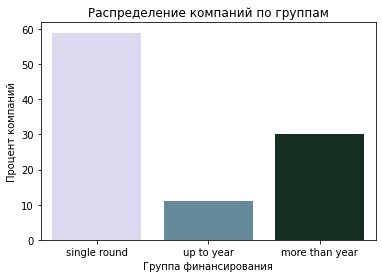

In [32]:
plt.figure(figsize=(6,4))
sns.barplot(x=count_percent.index, y=count_percent.values, palette=group_palette)
plt.ylabel('Процент компаний')
plt.xlabel('Группа финансирования')
plt.title('Распределение компаний по группам')
plt.show()

In [33]:
funding_sum = df.groupby('funding_group')['funding_total_usd'].sum().reindex(groups_order)
funding_percent = funding_sum / funding_sum.sum() * 100
funding_percent

funding_group
single round      30.587443
up to year         7.514048
more than year    61.898509
Name: funding_total_usd, dtype: float64

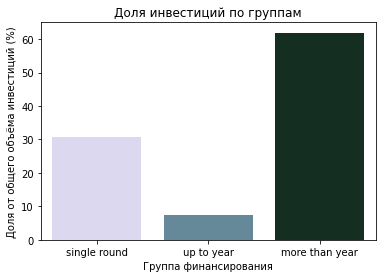

In [34]:
plt.figure(figsize=(6,4))
sns.barplot(x=funding_percent.index, y=funding_percent.values, palette=group_palette)
plt.ylabel('Доля от общего объёма инвестиций (%)')
plt.xlabel('Группа финансирования')
plt.title('Доля инвестиций по группам')
plt.show()

In [35]:
funding_percent/count_percent

funding_group
single round      0.518918
up to year        0.682877
more than year    2.059725
dtype: float64

**Вывод о группах компаний по срокам финансирования**

Можно заметить, что большая часть компаний (58,94%) имели всего один раунд финансирования, 11% компаний финансировались менее года, а 30,05% компаний финансировались более года. При этом если сравнивать данные группы по доле общих инвестиций, то можно заметить, что 61,9% всех средств были вложены в компании, финансируемые более года, при этом 30,59% средств были вложены в компании с единоразовым финансированием и только 7,51% в компании финансируемые более одного раза, но менее года (но если посмотреть на соотношения процентов компаний и доли общего рынка, можно заметить, что компании с единственным раундом финансирования привлекли на каждую меньше средств, чем компании финансируемые менее года) 
Можно сделать однозначный вывод, что компании, которые спонсировались более года собирают значительно (в разы) больше средств, чем компании в ждругих категориях. 

### 2.2 Выделение средних и нишевых сегментов рынка

In [36]:
df['market'] = df['market'].str.strip()
market_counts = df['market'].value_counts()
def segment_type(count):
    if count > 120:
        return 'массовый'
    elif 35 <= count <= 120:
        return 'средний'
    else:
        return 'нишевый'
segment_categories = market_counts.apply(segment_type)
segment_summary = segment_categories.value_counts()
segment_summary

нишевый     289
средний      57
массовый     49
Name: market, dtype: int64

In [37]:
segment_percent = (segment_summary/segment_summary.sum() * 100)
segment_percent

нишевый     73.164557
средний     14.430380
массовый    12.405063
Name: market, dtype: float64

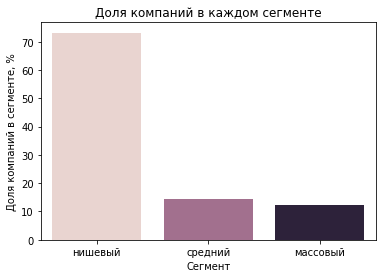

In [38]:
plt.figure(figsize=(6,4)) 
palette = sns.cubehelix_palette(n_colors=3, start=3)
sns.barplot(x=segment_percent.index, y=segment_percent.values, palette=palette) 
plt.xlabel('Сегмент') 
plt.ylabel('Доля компаний в сегменте, %') 
plt.title('Доля компаний в каждом сегменте') 
plt.show()

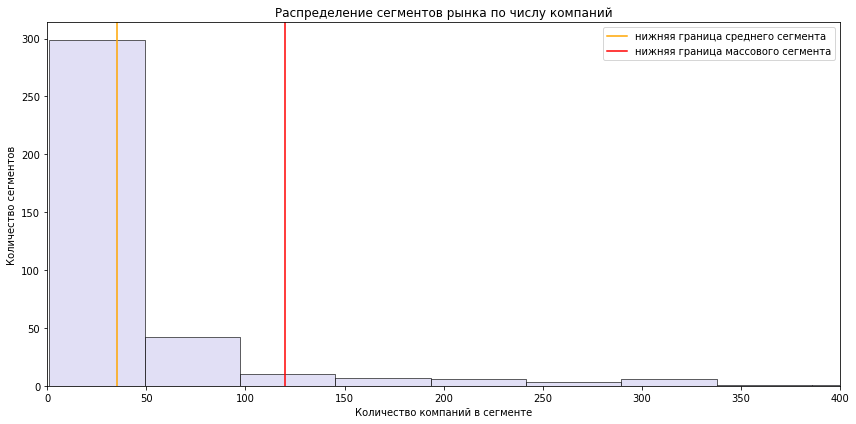

In [81]:
plt.figure(figsize=(12,6))

palette = sns.cubehelix_palette(n_colors=1, start=2)

sns.histplot(
    market_counts,
    bins=100,
    kde=False,
    color=palette[0]
)
plt.axvline(35, color='orange', linestyle='-', label='нижняя граница среднего сегмента')
plt.axvline(120, color='red', linestyle='-', label='нижняя граница массового сегмента')
plt.xlim(0, 400)
plt.xlabel('Количество компаний в сегменте')
plt.ylabel('Количество сегментов')
plt.title('Распределение сегментов рынка по числу компаний')
plt.legend()
plt.tight_layout()
plt.show()

In [39]:
market_counts = df['market'].value_counts()
market_replace = {}
for market, count in market_counts.items():
    if count > 120:
        continue
    elif 35 <= count <= 120:
        market_replace[market] = 'mid'
    else:
        market_replace[market] = 'niche'
df['market'] = df['market'].replace(market_replace)

По графику можно заметить, что большая часть сегментов компаний относятся к нишевым (к ним принадлежат менее 35 компаний). В дальнейшем исследовании значения в столбце датафрейма с сегментами были заменены на группы для среднего и нишевого сегментов, оригинальные значения (49 сегментов) остались лишь у массовых сегментов. При дальнейшем исследовании стоит учесть, что 87,59% компаний относятся к сегментам "mid" (средний)  и "niche" (нишевый) 

## Шаг 3. Работа с выбросами и анализ

### 3.1. Анализируем и помечаем выбросы в каждом из сегментов


In [40]:
df['funding_total_usd'].describe()

count    4.089800e+04
mean     1.590849e+07
std      1.686917e+08
min      1.000000e+00
25%      3.500000e+05
50%      2.000000e+06
75%      1.000000e+07
max      3.007950e+10
Name: funding_total_usd, dtype: float64

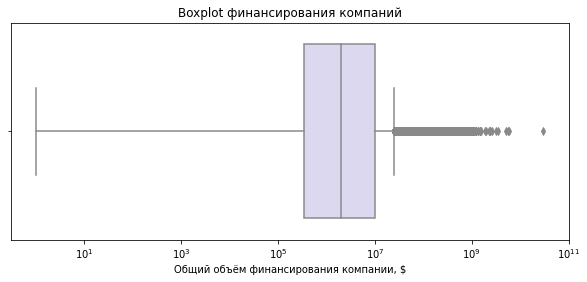

In [41]:
plt.figure(figsize=(10,4))
color = cubehelix_palette(n_colors=1, start=2)[0]
sns.boxplot(x=df['funding_total_usd'], color=color)
plt.xlabel('Общий объём финансирования компании, $')
plt.title('Boxplot финансирования компаний')
plt.xscale('log') 
plt.show()

In [42]:
df['funding_anomaly'] = False
for group, group_df in df.groupby('market'):
    Q1 = group_df['funding_total_usd'].quantile(0.25)
    Q3 = group_df['funding_total_usd'].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    df.loc[group_df.index, 'funding_anomaly'] = group_df['funding_total_usd'] > upper_bound

In [43]:
anomaly_ratio = round(
    df.groupby('market')['funding_anomaly']
      .mean()
      .sort_values(ascending=False) *100,
    2
)
top_anomaly_segments = anomaly_ratio.head(10)
top_anomaly_segments

market
Real Estate        17.20
Entertainment      16.67
Consulting         16.62
Search             16.49
Cloud Computing    16.45
Photography        16.18
SaaS               16.18
Technology         15.97
Video              15.96
niche              15.92
Name: funding_anomaly, dtype: float64

**Ввод об аномальных выбросах в столбце суммы финансирования**

По "ящику с усами" и данным можно заметить, что имеется очень много выбросов (график сильно смещен вправо). Очень большое стандартное отклонение(168.7 млн долларов). И мы можем увидеть, что большинство значений лежит в диапазоне от 350 000 долларов до 10 млн долларов с медианой в 2 млн долларов. Для анализа в условиях проекта необходимо уменьшить среднее отклонение. 

При этом самую большую долю аномально больших значений имеют компании, которые относятся к сегменту недвижимости (17,2%), развлечений (16,67%), консультирования (16,62%),  поиска (16,49%), а также облачных вычислений (16,45%). Также в топ-десять находятся сегменты фотография, SaaS (Software as a Service), технологии, видео и группа с нишевыми сегментами. Можно обратить внимание, что группа с средним сегментом не входит в топ-10 по этому параметру. 

Так как заказчику интересны стандартные значения, необходимо избавиться от такого большого количества аномально больших выбросов. 

### 3.2 Определяем границы рассматриваемого периода, отбрасываем аномалии


**Дата последней записи в датасете**

In [82]:
df['last_funding_at'].max()

Timestamp('2014-12-31 00:00:00')

**Распределение количества заказов по месяцам 2014 года**

In [44]:
df_2014 = df[df['last_funding_at'].dt.year == 2014]

df_2014['last_funding_at'].dt.month.value_counts().sort_index()

1     1178
2      947
3     1071
4     1077
5     1036
6     1229
7     1253
8     1064
9     1134
10    1138
11     730
12      52
Name: last_funding_at, dtype: int64

In [45]:
df = df[~df['funding_anomaly']].copy()

In [46]:
df['mid_year'] = df['mid_funding_at'].dt.year

In [47]:
rounds_per_year = (
    df
    .groupby('mid_year')['funding_rounds']
    .sum()
)
active_years = rounds_per_year[rounds_per_year >= 50].index
active_years

Float64Index([2000.0, 2001.0, 2002.0, 2003.0, 2004.0, 2005.0, 2006.0, 2007.0,
              2008.0, 2009.0, 2010.0, 2011.0, 2012.0, 2013.0, 2014.0],
             dtype='float64', name='mid_year')

In [48]:
df = df[df['mid_year'].isin(active_years)].copy()

Можно сделать вывод, что 2014 год полный, так как последняя запись была внесена в датасет 31.12.2014

Датафрейм был отфильтрован, оставлены годы в которые было проведено более 50 раундов финансирования (c 2000 по 2014 включительно) 

### 3.3. Анализ типов финансирования по объёму и популярности


In [49]:
funding_types = [
    'seed', 'venture', 'equity_crowdfunding', 'undisclosed',
    'convertible_note', 'debt_financing', 'angel', 'grant',
    'private_equity', 'post_ipo_equity', 'post_ipo_debt',
    'secondary_market', 'product_crowdfunding'
]

In [50]:
funding_totals = df[funding_types].sum().sort_values(ascending=False)
funding_totals

venture                 1.290909e+11
seed                    9.427312e+09
debt_financing          8.178153e+09
private_equity          4.843109e+09
angel                   2.478924e+09
undisclosed             2.100352e+09
grant                   1.978799e+09
post_ipo_equity         1.946452e+09
convertible_note        5.660394e+08
post_ipo_debt           2.867183e+08
equity_crowdfunding     2.379606e+08
product_crowdfunding    1.860939e+08
secondary_market        4.528580e+07
dtype: float64

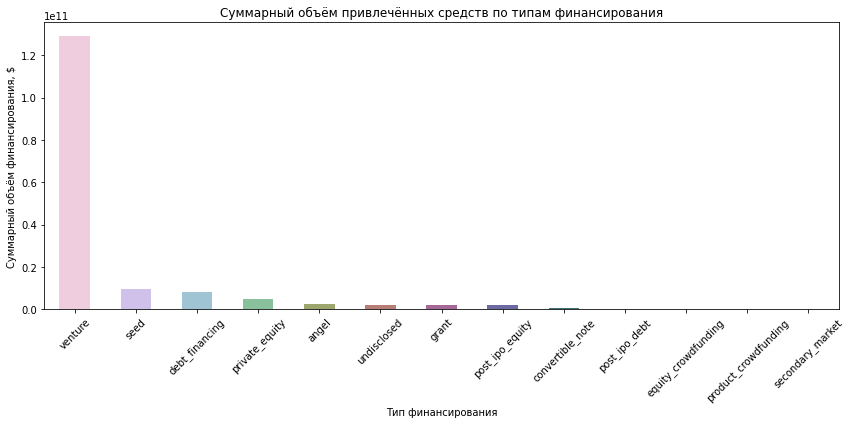

In [51]:
plt.figure(figsize=(12,6))
 
plt.ylabel('Суммарный объём финансирования, $')
plt.xlabel('Тип финансирования')
plt.title('Суммарный объём привлечённых средств по типам финансирования')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [52]:
funding_popularity = (
    (df[funding_types] > 0)
    .sum()
    .sort_values(ascending=False)
)

funding_popularity

venture                 18818
seed                    13370
debt_financing           3265
angel                    2935
grant                    1002
undisclosed               813
private_equity            634
convertible_note          521
equity_crowdfunding       515
product_crowdfunding      204
post_ipo_equity           164
post_ipo_debt              27
secondary_market            7
dtype: int64

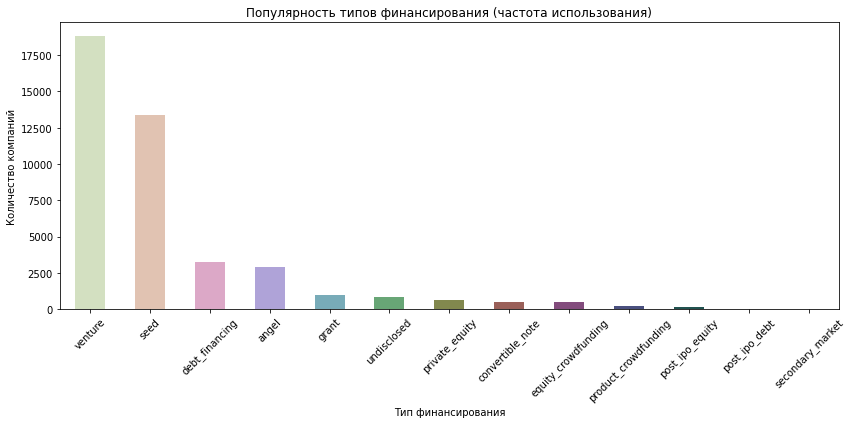

In [53]:
plt.figure(figsize=(12,6))
color = cubehelix_palette(n_colors=len(funding_popularity), start=3, rot=3)
funding_popularity.plot(kind='bar', color=color)
plt.ylabel('Количество компаний')
plt.xlabel('Тип финансирования')
plt.title('Популярность типов финансирования (частота использования)')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Можно заметить, что самый популярный тип финансирования - это венчурные инвестиции. Они лидируют как по количеству использования способа, так и по суммарному объему. При этом посевное финансирование находится на втором месте по распространенности, но при этом сильно отстает по сумме финансирования. Также распространенными и привлекшими большое количество средств являются долговое, ангел, и финансирование грантами. Также можно заметить, что пямые инвестиции находятся только на 7 месте по распространенности, но на 4 по общей сумме привлеченных инвестиций. 

In [54]:
returns_totals = (
    df2[funding_types]
    .sum()
    .sort_values(ascending=False)
)
returns_totals

venture                 40578.62
debt_financing           4734.85
private_equity           3587.33
seed                     2382.24
angel                    1509.23
post_ipo_equity          1104.96
undisclosed               730.88
post_ipo_debt              91.03
convertible_note           34.79
secondary_market            5.20
equity_crowdfunding         3.83
product_crowdfunding        1.86
grant                       0.00
dtype: float64

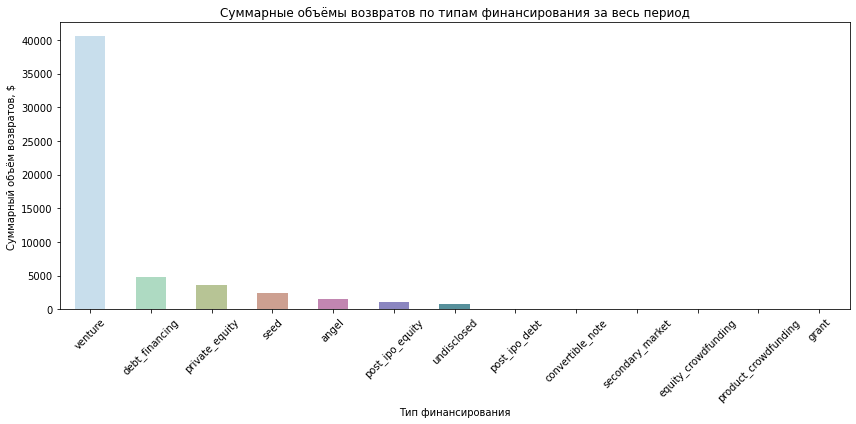

In [55]:
plt.figure(figsize=(12,6))
color = cubehelix_palette(n_colors=len(returns_totals), start=4, rot=3)
returns_totals.plot(kind='bar', color=color)

plt.ylabel('Суммарный объём возвратов, $')
plt.xlabel('Тип финансирования')
plt.title('Суммарные объёмы возвратов по типам финансирования за весь период')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Объемы возвратов так же выделяются у венчурных инвестиций. А так же у долгового, прямого, посевного и ангел финансирований выделяются объемы суммарных возвратов. 

## Шаг 4. Анализ динамики

### 4.1 Динамика предоставления финансирования по годам


In [56]:
df['avg_round_funding'] = df['funding_total_usd'] / df['funding_rounds']

In [57]:
df['mid_year'] = df['mid_funding_at'].dt.year

In [58]:
median_round_funding = df.groupby('mid_year')['avg_round_funding'].median()
median_round_funding

mid_year
2000    2.250000e+06
2001    1.570886e+06
2002    3.225000e+06
2003    1.500000e+06
2004    3.000000e+06
2005    4.500000e+06
2006    3.900000e+06
2007    2.879167e+06
2008    2.170744e+06
2009    1.498475e+06
2010    1.250000e+06
2011    8.676411e+05
2012    6.861246e+05
2013    5.590000e+05
2014    5.609315e+05
Name: avg_round_funding, dtype: float64

In [59]:
total_rounds_per_year = df.groupby('mid_year')['funding_rounds'].sum()
total_rounds_per_year

mid_year
2000      113.0
2001       66.0
2002       98.0
2003      125.0
2004      181.0
2005      948.0
2006     1849.0
2007     2842.0
2008     3663.0
2009     4617.0
2010     6134.0
2011     7576.0
2012     9706.0
2013    12880.0
2014     7118.0
Name: funding_rounds, dtype: float64

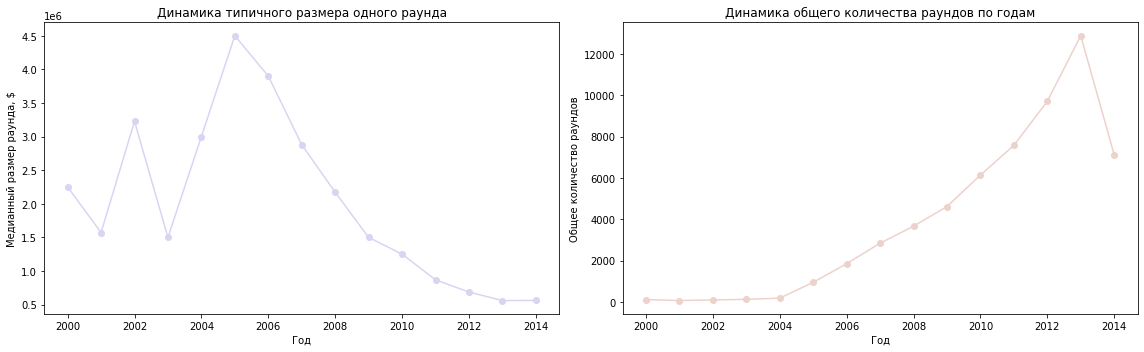

In [60]:
plt.figure(figsize=(16,5))
plt.subplot(1,2,1)
color1 = cubehelix_palette(n_colors=1, start=2)
color2 = cubehelix_palette(n_colors=1, start=3)
median_round_funding.plot(marker='o', color=color1)
plt.title('Динамика типичного размера одного раунда')
plt.xlabel('Год')
plt.ylabel('Медианный размер раунда, $')
plt.subplot(1,2,2)
total_rounds_per_year.plot(marker='o', color=color2)
plt.title('Динамика общего количества раундов по годам')
plt.xlabel('Год')
plt.ylabel('Общее количество раундов')

plt.tight_layout()
plt.show()

По графикам явно видно, что размер раунда имеет большую тенденцию к уменьшению и свой максимум зафиксировал в 2005 году. А динамика количества раундов по годам показывала рост, но начала снижаться в 2013 году. В 2014 году можно заметить небольшую тенденцию к увеличению размера раунда, а также явное падение общего количества раундов. 

### 4.2 Динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов


In [61]:
df_massive = df_mass = df[~df['market'].isin(['niche', 'mid'])]

In [62]:
pivot_funding = df_massive.pivot_table(
    index='mid_year',
    columns='market',
    values='funding_total_usd',
    aggfunc='sum'
)

pivot_funding

market,Advertising,Analytics,Apps,Automotive,Big Data,Biotechnology,Clean Technology,Cloud Computing,Consulting,Curated Web,...,Social Media,Social Network Media,Software,Sports,Startups,Technology,Travel,Unknown,Video,Web Hosting
mid_year,,,,,,,,,,,,,,,,,,,,,
2000,14470000.0,14822803.0,NaN,NaN,NaN,NaN,NaN,11500000.0,4500000.0,1000000.0,...,NaN,NaN,3.173264e+07,NaN,NaN,NaN,50230.0,1839560.0,NaN,95343090.0
2001,8778321.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,305000.0,...,650000.0,NaN,2.781135e+07,NaN,NaN,22160000.0,NaN,10160345.0,NaN,15000000.0
2002,24500000.0,7500000.0,NaN,NaN,NaN,NaN,3.439044e+07,NaN,NaN,4650000.0,...,NaN,NaN,1.010264e+08,200000.0,NaN,11000000.0,NaN,242132.0,NaN,NaN
2003,10500000.0,3840000.0,NaN,4530000.0,NaN,8.553118e+07,5.035294e+07,NaN,NaN,2550000.0,...,5000.0,NaN,6.608604e+07,NaN,NaN,NaN,NaN,4155202.0,5000000.0,NaN
2004,6000000.0,3000000.0,NaN,NaN,NaN,9.718486e+07,5.042795e+07,NaN,NaN,27050000.0,...,6850000.0,NaN,1.408238e+08,NaN,NaN,1750000.0,10230000.0,10847977.0,14704000.0,27000000.0
2005,127196022.0,79014044.0,NaN,22500000.0,NaN,4.800636e+08,1.942000e+07,NaN,44862000.0,53450000.0,...,14780000.0,5200000.0,9.930766e+08,1882200.0,NaN,50728425.0,27830000.0,28384331.0,6470551.0,483332632.0
2006,299299458.0,139701311.0,1310600.0,12660000.0,NaN,9.035005e+08,1.314739e+08,9951809.0,23965548.0,164673698.0,...,60169880.0,5245100.0,1.646869e+09,7000000.0,NaN,22791000.0,11700000.0,46049840.0,35171772.0,649959267.0
2007,556704331.0,98829000.0,NaN,37712601.0,7780000.0,1.704078e+09,7.497112e+08,20354343.0,70346345.0,314704515.0,...,89022516.0,24104021.0,1.686116e+09,16401580.0,NaN,180190209.0,13950000.0,35532468.0,85150644.0,361121449.0
2008,622673464.0,208077840.0,4300000.0,59478635.0,2452515.0,1.716033e+09,3.165808e+09,44375000.0,19061080.0,336500027.0,...,76034534.0,10998076.0,1.365006e+09,9554790.0,5010387.0,277726238.0,54905631.0,45345010.0,37865177.0,781623731.0


In [63]:
years_for_check = [2013, 2014]
pivot_for_check = pivot_funding.loc[years_for_check]
segments_growth_2014 = pivot_for_check.loc[2014] > pivot_for_check.loc[2013]
segments_growth_2014 = segments_growth_2014[segments_growth_2014].index.tolist()
segments_growth_2014

['Apps',
 'Big Data',
 'Design',
 'Internet',
 'Manufacturing',
 'Medical',
 'Real Estate',
 'SaaS',
 'Startups',
 'Technology',
 'Unknown']

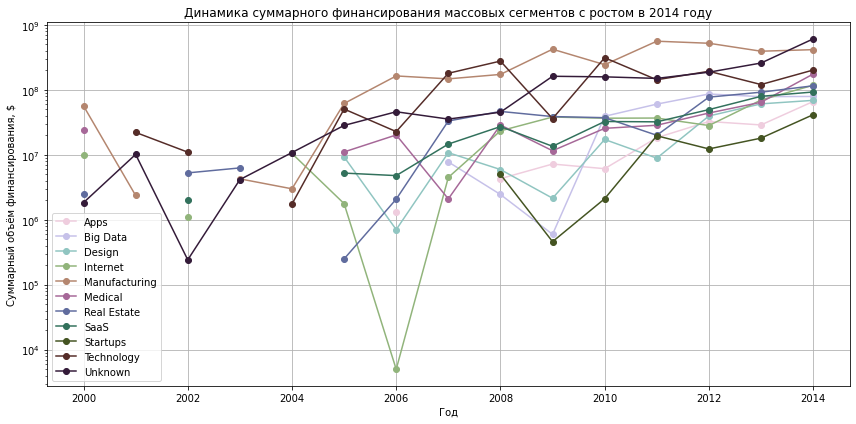

In [64]:
plt.figure(figsize=(12,6))
color = cubehelix_palette(n_colors=len(segments_growth_2014), start=2, rot=3)
for i, segment in enumerate(segments_growth_2014):
    plt.plot(pivot_funding.index, pivot_funding[segment], marker='o', label=segment, color=color[i])

plt.xlabel('Год')
plt.ylabel('Суммарный объём финансирования, $')
plt.title('Динамика суммарного финансирования массовых сегментов с ростом в 2014 году')
plt.legend()
plt.yscale('log')
plt.grid(True)
plt.tight_layout()
plt.show()

Самый быстрый уверенный рост к 2014 году показывают следующие отрасли: медицина, приложения, недвижимость, SaaS, интернет. Самый большой рост виден у компаний с неизвестными отраслями, что скорее всего объясняется исключительно спецификой сбора данных. 

### 4.3 Годовая динамика доли возвращённых средств по типам финансирования

In [65]:
df['year'] = df['mid_funding_at'].dt.year

In [66]:
funding_yearly = (
    df
    .groupby('year')[funding_types]
    .sum()
)

In [67]:
returns_yearly = df2[funding_types]

In [68]:
returns_yearly = returns_yearly.reindex(funding_yearly.index)

In [69]:
return_ratio = returns_yearly / (funding_yearly + 1e-60)

In [70]:
return_ratio = return_ratio.where(
    (return_ratio >= 0) & (return_ratio <= 1)
)
return_ratio

,seed,venture,equity_crowdfunding,undisclosed,convertible_note,debt_financing,angel,grant,private_equity,post_ipo_equity,post_ipo_debt,secondary_market,product_crowdfunding
year,,,,,,,,,,,,,
2000,9.964712e-07,1.689219e-07,0.000000e+00,6.970424e-07,0.000000e+00,6.185714e-07,2.669564e-07,0.0,0.000000e+00,2.710694e-07,0.000000e+00,2.591054e-08,0.000000e+00
2001,1.079592e-06,1.079905e-07,0.000000e+00,5.874833e-07,6.666667e-09,7.702578e-07,1.180000e-06,0.0,0.000000e+00,NaN,0.000000e+00,NaN,0.000000e+00
2002,6.297066e-07,6.822818e-07,0.000000e+00,6.088783e-07,NaN,2.233882e-07,1.136667e-06,0.0,2.013333e-07,1.133333e-06,0.000000e+00,NaN,0.000000e+00
2003,5.052762e-07,6.282600e-07,0.000000e+00,9.143969e-07,NaN,1.038095e-06,6.057203e-07,0.0,NaN,NaN,0.000000e+00,NaN,0.000000e+00
2004,5.484755e-07,8.370091e-07,0.000000e+00,5.275593e-07,NaN,4.396978e-07,8.335043e-07,0.0,NaN,NaN,0.000000e+00,NaN,0.000000e+00
2005,6.746954e-07,5.465859e-07,0.000000e+00,1.071992e-06,NaN,3.449644e-07,5.098940e-07,0.0,4.800000e-07,7.318565e-07,0.000000e+00,NaN,0.000000e+00
2006,9.253718e-07,3.436776e-07,2.036317e-07,7.594382e-07,1.663181e-07,8.037720e-07,6.748530e-07,0.0,9.354530e-07,NaN,0.000000e+00,NaN,0.000000e+00
2007,3.661533e-07,2.972428e-07,NaN,5.049708e-07,2.280972e-07,6.024881e-07,8.178375e-07,0.0,5.790563e-07,2.030000e-06,0.000000e+00,NaN,0.000000e+00
2008,2.970831e-07,1.908726e-07,NaN,3.420604e-07,5.978832e-08,9.274838e-07,4.124756e-07,0.0,6.799254e-07,2.341111e-06,0.000000e+00,NaN,0.000000e+00


In [71]:
selected_types = [
    'venture',
    'debt_financing',
    'private_equity',
    'seed',
    'angel'
]

ratio_selected = return_ratio[selected_types]

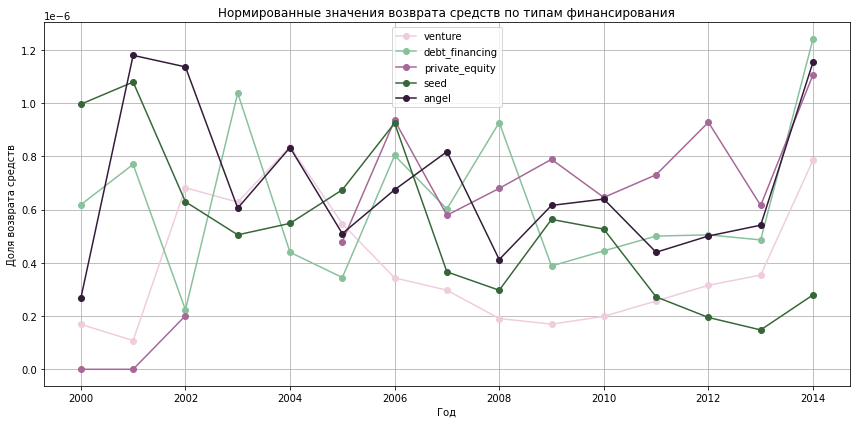

In [72]:
plt.figure(figsize=(12,6))

palette = sns.cubehelix_palette(n_colors=len(selected_types), start=2, rot=3)

for i, col in enumerate(selected_types):
    plt.plot(
        ratio_selected.index,
        ratio_selected[col],
        marker='o',
        label=col,
        color=palette[i]
    )

plt.xlabel('Год')
plt.ylabel('Доля возврата средств')
plt.title('Нормированные значения возврата средств по типам финансирования')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Все виды финансирования кроме посевных инвестиций показывают выраженный рост доли возврата средств. Самый большой у долговых, ангел и прямых инвестиций. Венчурные инвестиции показывают самый стабильный рост, не прекращающийся с 2009 года. 


## Шаг 5. Итоговый вывод и рекомендации

Была произведена предобработка данных. Обработаны пропуски и дубликаты, все данные приведены к необходимым типам. Столбцы приведены к общему виду. Удалены все лишние пробелы в датасете. Удалены нерелевантные данные. 

Выделены группы по срокам финансирования (единичное, до года, более года). Сделан вывод, что компании, которые спонсировались более года собирают значительно (в разы) больше средств, чем компании в других категориях. 

Выделены средние и нишевые сегменты рынка, значения в датасете были заменены для них на "mid" и "niche", свои значения сохранили только массовые сегменты, чтобы провести корректный анализ с выделением конкретных сегментов. Однако стоит учесть, что большая часть сегментов относятся к средним и нишевым. 

Была проведена работа с выбросами, были удалены аномально большие значения, искажавшие средние результаты. 

Были изучены типы финансирования по объемам привлеченного, частоте использования и проценту возвратов. Можно сделать вывод, что венчурные инвестиции являются самым популярным методом финансирования стартапов, а также самым стабильным, имеющим наибольшее количество привлеченных средств и возвратов инвесторам. 


Также был проведен анализ динамики предоставления финансов по годам, из чего был сделан вывод, что к 2014 году наблюдается общее снижение как размера одного раунда (с тенденцией к небольшому повышению к 2014). А также резкое падение общего количества раундов, начавшееся в 2013. 

Также проанализирована динамика размера общего финансирования по массовым сегментам рынка для растущих в 2014 году сегментов. Были изучены отрасли финансирования. Перспективными отраслями можно считать следующие: медицина, приложения, недвижимость, SaaS, интернет. Так как они показывают стабильный, достаточно быстрый рост объемов их финансирования. 

Можно сделать общий вывод, что полученные данные не протеворечат друг другу, однако стоит учитывать, что пусть общая тенденция к 2013-2014 общего привлечения инвестиций показывает снижение, отдельные отрасли и типы финансирования показывают уверенный рост. Следовательно стоит сконцентрироваться на: финансировании проектов с длительным циклом более года, венчурных (а также долговых, ангел и прямых в качестве альтернативы) инвестициях, и таких отраслях, как медицина, приложения, недвижимость, SaaS, интернет. 